# DRStageNet on handheld fundus images: analysis code

Analysis for *Artificial Intelligence vs. Human Specialists for Diabetic Retinopathy Grading: Real-World Validation with a Handheld Fundus Camera and Ground Truth Benchmarking* (PLOS ONE).

The notebook reproduces every number, table and figure in the manuscript and its supporting information from one per-image file, `data/final_dataframe_with_edema.csv`. That file is **not** distributed with this repository (see the README for data access). Run it top to bottom; results are written to `outputs/`.

| Section | Manuscript item |
|---|---|
| 1 | Cohort, exclusions, derived variables; S1 Fig (flow diagram) |
| 2 | Table 1 |
| 3 | Agreement between the reference-standard graders; kappa context (Discussion) |
| 4 | Patient-level cluster bootstrap used for all confidence intervals |
| 5 | Five-class ICDR grading: text metrics, Table 2, S1 Table, S2 Fig, S2 Table |
| 6 | Referable DR: Table 3, Figure 3, macular-edema-only cases, S4 Table, S6 Table, S3 Table |
| 7 | Paired comparisons between the model and each reader: S5 Table |
| 8 | Figure 1 |
| 9 | Error analysis of the five-class grades |
| 10 | Figure 2 (needs the retinal images; skipped if they are absent) |
| 11 | Check of the key results reported in the manuscript |

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, cohen_kappa_score, confusion_matrix,
                             f1_score, precision_recall_fscore_support)
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.proportion import proportion_confint

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

# ---------- paths ----------
DATA_DIR   = Path("data")
OUT_DIR    = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)
DATA_CSV   = DATA_DIR / "final_dataframe_with_edema.csv"   # one row per image (not distributed)
REVIEW_CSV = DATA_DIR / "error_review_sheet_v1.csv"        # qualitative review of the model's errors (not distributed)
IMAGES_DIR = DATA_DIR / "images"                           # retinal images, only for Figure 2 (not distributed)

# ---------- study definitions ----------
SEED        = 42
N_BOOT      = 2000      # patient-level cluster bootstrap replicates
RDR_CUTOFF  = 2         # referable DR = ICDR >= 2 and/or macular edema
ICDR_LABELS = [0, 1, 2, 3, 4]
ICDR_NAMES  = ["No DR", "Mild NPDR", "Moderate NPDR", "Severe NPDR", "PDR"]

# ---------- columns of the data file ----------
PATIENT, IMAGE = "pat_id", "extended_img_id_eyer"
GT_ICDR, GT_EDEMA = "gt_icdr", "gt_edema"            # adjudicated reference standard
AI_SCORE, AI_ICDR = "DRStageNetPred_eyer", "LabelPred_eyer"   # DRStageNet continuous output and grade
# independent readers (human benchmark), in the order of the manuscript tables: name -> (ICDR column, edema column)
READERS = {"Reader 1": ("icdr_eran", "edema_eran"),
           "Reader 2": ("icdr_meishar", "edema_meishar"),
           "Reader 3": ("icdr_dinah", "edema_dinah")}
# the two graders who set the reference standard, before adjudication
GRADER_A, GRADER_B = ("icdr_luis", "edema_luis"), ("icdr_lzr", "edema_lzr")

# ---------- acquisition counts upstream of the data file (for the flow diagram) ----------
# 489 macula-centred Eyer images from 285 patients were acquired between March and September 2022.
# 50 images of previously treated eyes were removed at the initial screening, before the data file was built;
# the data file holds the remaining images, in which 7 further treated eyes were flagged at regrading.
N_ACQUIRED_IMG, N_ACQUIRED_PAT = 489, 285
N_TREATED_INITIAL = 50
STUDY_PERIOD = "March to September 2022"

## 1. Cohort and derived variables

Exclusions: eyes with previous DR treatment (`post_treatement == "yes"`) and ungradable images (`quality == "no"`).

- **Reference referable DR (rDR)** = reference ICDR ≥ 2 **or** macular edema.
- **Model rDR** = predicted ICDR ≥ 2. DRStageNet has no macular edema output.
- **Reader rDR** = reader's ICDR ≥ 2 **or** macular edema marked by the reader.
- A missing edema value is treated as absent.

In [2]:
raw = pd.read_csv(DATA_CSV)
treated    = raw["post_treatement"].eq("yes")
ungradable = raw["quality"].eq("no")
df = raw[~treated & ~ungradable].reset_index(drop=True)

def to_rdr(icdr, edema=None):
    out = icdr >= RDR_CUTOFF
    if edema is not None:
        out = out | edema.fillna(0).eq(1)
    return out.astype(int)

df["gt_rdr"] = to_rdr(df[GT_ICDR], df[GT_EDEMA])
df["ai_rdr"] = to_rdr(df[AI_ICDR])
RATERS = [("AI", AI_ICDR, "ai_rdr")]            # (label, ICDR column, rDR column)
for name, (icdr_col, edema_col) in READERS.items():
    df[f"rdr_{name}"] = to_rdr(df[icdr_col], df[edema_col])
    RATERS.append((name, icdr_col, f"rdr_{name}"))
NAMES = [r[0] for r in RATERS]

assert N_ACQUIRED_IMG - N_TREATED_INITIAL == len(raw), "acquisition counts do not match the data file"
assert df[[GT_ICDR] + [r[1] for r in RATERS]].notna().all().all(), "missing ICDR grade"

n_treated, n_ungradable = N_TREATED_INITIAL + int(treated.sum()), int((~treated & ungradable).sum())
untreated = raw[~treated]
flow = pd.DataFrame({
    "images":   [N_ACQUIRED_IMG, n_treated, len(untreated), n_ungradable, len(df)],
    "patients": [N_ACQUIRED_PAT, np.nan, untreated[PATIENT].nunique(), np.nan, df[PATIENT].nunique()]},
    index=["Acquired", "Excluded: previous treatment", "Without previous treatment", "Excluded: ungradable", "Analysed"])
flow.to_csv(OUT_DIR / "cohort_flow.csv")
flow

,images,patients
Acquired,489,285.0
Excluded: previous treatment,57,NaN
Without previous treatment,432,259.0
Excluded: ungradable,17,NaN
Analysed,415,252.0


### S1 Fig. Flow diagram

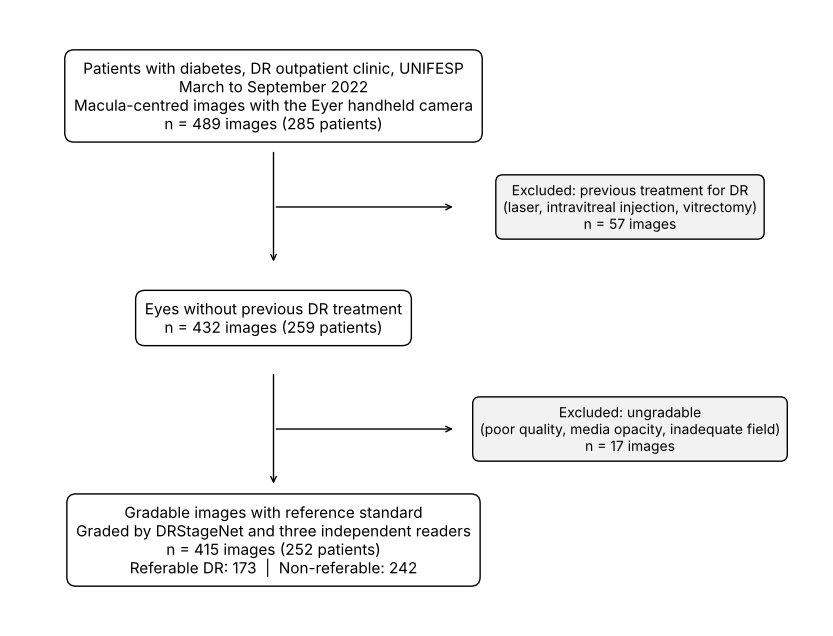

In [3]:
n_pat = lambda d: d[PATIENT].nunique()
boxes = [  # (main box, exclusion box or None)
    (f"Patients with diabetes, DR outpatient clinic, UNIFESP\n{STUDY_PERIOD}\n"
     f"Macula-centred images with the Eyer handheld camera\nn = {N_ACQUIRED_IMG} images ({N_ACQUIRED_PAT} patients)", None),
    (f"Eyes without previous DR treatment\nn = {len(untreated)} images ({n_pat(untreated)} patients)",
     f"Excluded: previous treatment for DR\n(laser, intravitreal injection, vitrectomy)\nn = {n_treated} images"),
    (f"Gradable images with reference standard\nGraded by DRStageNet and three independent readers\n"
     f"n = {len(df)} images ({n_pat(df)} patients)\n"
     f"Referable DR: {df['gt_rdr'].sum()}  |  Non-referable: {(1 - df['gt_rdr']).sum()}",
     f"Excluded: ungradable\n(poor quality, media opacity, inadequate field)\nn = {n_ungradable} images"),
]
X_MAIN, X_SIDE, ys = 3.4, 8.0, [7.4, 4.3, 1.2]
fig, ax = plt.subplots(figsize=(10.5, 8))
ax.axis("off"); ax.set_xlim(0, 10.5); ax.set_ylim(0, 8.6)
for (main, side), y in zip(boxes, ys):
    ax.text(X_MAIN, y, main, ha="center", va="center", fontsize=11, bbox=dict(boxstyle="round,pad=0.6", fc="white", ec="black"))
    if side:
        ax.text(X_SIDE, y + 1.55, side, ha="center", va="center", fontsize=10,
                bbox=dict(boxstyle="round,pad=0.5", fc="#f2f2f2", ec="black"))
        ax.annotate("", xy=(5.75, y + 1.55), xytext=(X_MAIN, y + 1.55), arrowprops=dict(arrowstyle="->"))
for y0, y1 in zip(ys[:-1], ys[1:]):
    ax.annotate("", xy=(X_MAIN, y1 + 0.75), xytext=(X_MAIN, y0 - 0.75), arrowprops=dict(arrowstyle="->"))
fig.savefig(OUT_DIR / "S1_Fig_flow_diagram.tif", dpi=300, bbox_inches="tight", facecolor="white",
            pil_kwargs={"compression": "tiff_lzw"})
plt.show()

## 2. Table 1. Clinical and demographic characteristics

In [4]:
pat = df.drop_duplicates(PATIENT)
n_pct = lambda mask, denom: f"{int(mask.sum())} ({mask.sum() / denom * 100:.1f})"

rows = [("Patient level", "", "", f"n = {len(pat)} patients")]
for label, col in [("Age, years", "age"), ("Diabetes duration, years", "dm_time")]:
    rows.append((label, "", int(pat[col].isna().sum()), f"{pat[col].mean():.1f} (± {pat[col].std():.1f})"))
for label, col, levels in [("Sex", "sex", ["female", "male"]), ("Race", "race", ["asian", "black", "mixed", "white"]),
                           ("Hypertension", "hypertension", [0, 1])]:
    for lv in levels:
        rows.append((label, {0: "No", 1: "Yes"}.get(lv, str(lv).capitalize()), int(pat[col].isna().sum()),
                     n_pct(pat[col].eq(lv), len(pat))))
rows.append(("Image level", "", "", f"n = {len(df)} images"))
for g, name in zip(ICDR_LABELS, ICDR_NAMES):
    rows.append(("ICDR", f"{g} - {name}", 0, n_pct(df[GT_ICDR].eq(g), len(df))))
rows.append(("Macular edema", "Present", int(df[GT_EDEMA].isna().sum()), n_pct(df[GT_EDEMA].eq(1), len(df))))
rows.append(("Referable DR", "Yes", 0, n_pct(df["gt_rdr"].eq(1), len(df))))

table1 = pd.DataFrame(rows, columns=["Variable", "Level", "Missing", "Value, mean (± SD) or n (%)"])
table1.to_csv(OUT_DIR / "Table1.csv", index=False)
table1

,Variable,Level,Missing,"Value, mean (± SD) or n (%)"
0,Patient level,,,n = 252 patients
1,"Age, years",,0,55.9 (± 17.9)
2,"Diabetes duration, years",,6,15.3 (± 9.2)
3,Sex,Female,0,139 (55.2)
4,Sex,Male,0,113 (44.8)
5,Race,Asian,3,6 (2.4)
6,Race,Black,3,53 (21.0)
7,Race,Mixed,3,105 (41.7)
8,Race,White,3,85 (33.7)
9,Hypertension,No,0,90 (35.7)


## 3. Reference standard: agreement between the two graders

Agreement before adjudication, on the analysed images. *Unweighted* kappa is Cohen's kappa without weights.

The second table puts the model's quadratic weighted kappa against the adjudicated reference (0.908) beside the agreement between the two graders (0.889), the model against each grader alone, and each grader against the adjudicated reference, to which they contributed (Discussion).

In [5]:
(a_icdr, a_edema), (b_icdr, b_edema) = GRADER_A, GRADER_B
intergrader = pd.Series({
    "ICDR unweighted kappa":            cohen_kappa_score(df[a_icdr], df[b_icdr]),
    "ICDR quadratic weighted kappa":    cohen_kappa_score(df[a_icdr], df[b_icdr], weights="quadratic"),
    "Macular edema kappa":              cohen_kappa_score(df[a_edema].fillna(0), df[b_edema].fillna(0)),
    "Images with different ICDR grades (adjudicated)": (df[a_icdr] != df[b_icdr]).sum(),
}).round(3)
intergrader.to_csv(OUT_DIR / "intergrader_agreement.csv", header=["value"])
display(intergrader.to_frame("value"))

qk = lambda a, b: cohen_kappa_score(df[a].astype(int), df[b].astype(int), weights="quadratic")
kappa_ctx = pd.Series({
    "Grader A vs Grader B (before adjudication)": qk(a_icdr, b_icdr),
    "DRStageNet vs adjudicated reference":        qk(AI_ICDR, GT_ICDR),
    "DRStageNet vs Grader A alone":               qk(AI_ICDR, a_icdr),
    "DRStageNet vs Grader B alone":               qk(AI_ICDR, b_icdr),
    "Grader A vs adjudicated reference":          qk(a_icdr, GT_ICDR),
    "Grader B vs adjudicated reference":          qk(b_icdr, GT_ICDR),
}, name="Quadratic weighted kappa").round(3)
kappa_ctx.to_csv(OUT_DIR / "kappa_context.csv")
kappa_ctx.to_frame()

,value
ICDR unweighted kappa,0.734
ICDR quadratic weighted kappa,0.889
Macular edema kappa,0.874
Images with different ICDR grades (adjudicated),69.000


,Quadratic weighted kappa
Grader A vs Grader B (before adjudication),0.889
DRStageNet vs adjudicated reference,0.908
DRStageNet vs Grader A alone,0.898
DRStageNet vs Grader B alone,0.882
Grader A vs adjudicated reference,0.927
Grader B vs adjudicated reference,0.936


## 4. Patient-level cluster bootstrap

252 patients contribute 415 images, and fellow eyes are correlated, so the patient is the unit of inference. Patients are resampled with replacement and all images of a sampled patient are kept (2,000 replicates, percentile intervals). The same replicates are used for every rater, which also gives the confidence intervals of the paired differences (section 7).

Exceptions, reported with image-level Wilson intervals: per-class sensitivity and specificity (S2 Table) and the secondary analyses in S4 and S6 Tables, which include proportions with no observed failures, for which a bootstrap interval is degenerate.

In [6]:
def all_metrics(d):
    # every metric of Tables 2 and 3 for the model and the readers, on a (possibly resampled) data frame
    out = {}
    yt_m, yt_b = d[GT_ICDR].to_numpy(), d["gt_rdr"].to_numpy()
    for name, icdr_col, rdr_col in RATERS:
        yp_m, yp_b = d[icdr_col].to_numpy().astype(int), d[rdr_col].to_numpy()
        tp = ((yp_b == 1) & (yt_b == 1)).sum(); tn = ((yp_b == 0) & (yt_b == 0)).sum()
        fp = ((yp_b == 1) & (yt_b == 0)).sum(); fn = ((yp_b == 0) & (yt_b == 1)).sum()
        out[(name, "MC Accuracy")]           = (yp_m == yt_m).mean() * 100
        out[(name, "MC Weighted F1")]        = f1_score(yt_m, yp_m, average="weighted", zero_division=0)
        out[(name, "MC Kappa (unweighted)")] = cohen_kappa_score(yt_m, yp_m)
        out[(name, "MC Kappa (quadratic)")]  = cohen_kappa_score(yt_m, yp_m, weights="quadratic")
        out[(name, "rDR Accuracy")]          = (tp + tn) / len(d) * 100
        out[(name, "rDR Sensitivity")]       = tp / (tp + fn) * 100
        out[(name, "rDR Specificity")]       = tn / (tn + fp) * 100
        out[(name, "rDR PPV")]               = tp / (tp + fp) * 100
        out[(name, "rDR NPV")]               = tn / (tn + fn) * 100
        out[(name, "rDR F1")]                = 2 * tp / (2 * tp + fp + fn)
        out[(name, "rDR Kappa")]             = cohen_kappa_score(yt_b, yp_b)
    return pd.Series(out)

point = all_metrics(df)
rng = np.random.default_rng(SEED)
groups = list(df.groupby(PATIENT).indices.values())     # row positions of each patient's images
reps = pd.DataFrame([all_metrics(df.iloc[np.concatenate([groups[i] for i in rng.integers(0, len(groups), len(groups))])])
                     for _ in range(N_BOOT)])

ci = pd.DataFrame({"estimate": point, "ci_low": reps.quantile(0.025), "ci_high": reps.quantile(0.975)})
ci.index.names = ["Rater", "Metric"]
ci.round(4).to_csv(OUT_DIR / "cluster_bootstrap_ci.csv")

def ci_str(rater, metric, nd):
    r = ci.loc[(rater, metric)]
    return f"{r['estimate']:.{nd}f} [{r['ci_low']:.{nd}f}–{r['ci_high']:.{nd}f}]"

print(f"Patients: {len(groups)} | images: {len(df)} | patients with both eyes: {sum(len(g) == 2 for g in groups)} | replicates: {N_BOOT}")

Patients: 252 | images: 415 | patients with both eyes: 163 | replicates: 2000


## 5. Five-class ICDR grading

In [7]:
def multiclass_metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"Accuracy (%)": accuracy_score(y_true, y_pred) * 100, "Macro precision": p, "Macro recall": r, "Macro F1": f,
            "Weighted F1": f1_score(y_true, y_pred, average="weighted"),
            "Unweighted kappa": cohen_kappa_score(y_true, y_pred),
            "Quadratic weighted kappa": cohen_kappa_score(y_true, y_pred, weights="quadratic")}

multi = pd.DataFrame({name: multiclass_metrics(df[GT_ICDR], df[col].astype(int)) for name, col, _ in RATERS}).T
multi.round(3).to_csv(OUT_DIR / "multiclass_metrics.csv")
display(multi.round(3))

table2 = pd.DataFrame({
    "Accuracy (%) [95% CI]":             [ci_str(n, "MC Accuracy", 1) for n in NAMES],
    "Weighted F1 [95% CI]":              [ci_str(n, "MC Weighted F1", 3) for n in NAMES],
    "Unweighted kappa [95% CI]":         [ci_str(n, "MC Kappa (unweighted)", 3) for n in NAMES],
    "Quadratic weighted kappa [95% CI]": [ci_str(n, "MC Kappa (quadratic)", 3) for n in NAMES],
}, index=NAMES)
table2.to_csv(OUT_DIR / "Table2.csv")
print("Table 2"); table2

,Accuracy (%),Macro precision,Macro recall,Macro F1,Weighted F1,Unweighted kappa,Quadratic weighted kappa
AI,79.518,0.676,0.622,0.635,0.793,0.679,0.908
Reader 1,64.337,0.518,0.439,0.432,0.594,0.393,0.707
Reader 2,70.120,0.562,0.586,0.543,0.703,0.544,0.884
Reader 3,63.133,0.547,0.589,0.529,0.654,0.466,0.836


Table 2


,Accuracy (%) [95% CI],Weighted F1 [95% CI],Unweighted kappa [95% CI],Quadratic weighted kappa [95% CI]
AI,79.5 [75.3–83.5],0.793 [0.749–0.835],0.679 [0.619–0.738],0.908 [0.881–0.931]
Reader 1,64.3 [59.1–69.2],0.594 [0.532–0.653],0.393 [0.330–0.453],0.707 [0.630–0.767]
Reader 2,70.1 [65.4–74.8],0.703 [0.654–0.750],0.544 [0.485–0.599],0.884 [0.856–0.907]
Reader 3,63.1 [58.1–67.9],0.654 [0.602–0.700],0.466 [0.404–0.522],0.836 [0.789–0.872]


### S1 Table and S2 Fig. Five-by-five confusion matrices

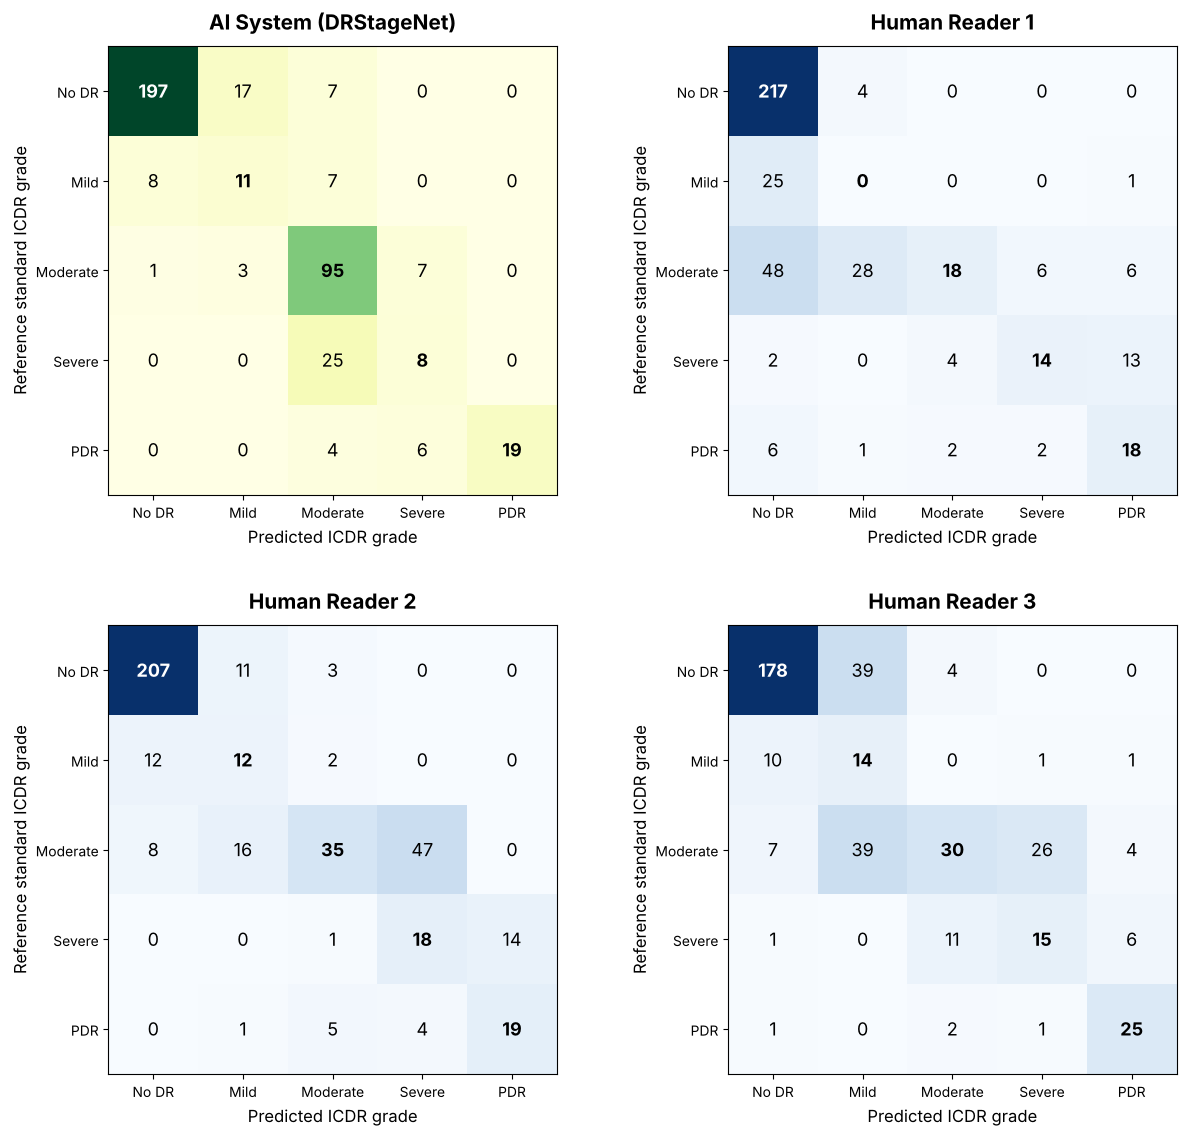

,No DR,Mild NPDR,Moderate NPDR,Severe NPDR,PDR
Reference standard,,,,,
No DR,197,17,7,0,0
Mild NPDR,8,11,7,0,0
Moderate NPDR,1,3,95,7,0
Severe NPDR,0,0,25,8,0
PDR,0,0,4,6,19


In [8]:
cms = {name: confusion_matrix(df[GT_ICDR], df[col].astype(int), labels=ICDR_LABELS) for name, col, _ in RATERS}
s1_table = pd.concat({name: pd.DataFrame(cm, index=pd.Index(ICDR_NAMES, name="Reference standard"), columns=ICDR_NAMES)
                      for name, cm in cms.items()}, names=["Rater"])
s1_table.to_csv(OUT_DIR / "S1_Table_confusion_matrices_5x5.csv")

fig, axes = plt.subplots(2, 2, figsize=(13, 12))
short = ["No DR", "Mild", "Moderate", "Severe", "PDR"]
for ax, (name, cm) in zip(axes.flat, cms.items()):
    ax.imshow(cm, cmap="YlGn" if name == "AI" else "Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v:d}", ha="center", va="center", fontsize=13,
                fontweight="bold" if i == j else "normal", color="white" if v > cm.max() / 2 else "black")
    ax.set_xticks(range(5)); ax.set_xticklabels(short); ax.set_yticks(range(5)); ax.set_yticklabels(short)
    ax.set_title("AI System (DRStageNet)" if name == "AI" else f"Human {name}", fontsize=15, fontweight="bold", pad=12)
    ax.set_xlabel("Predicted ICDR grade", fontsize=12); ax.set_ylabel("Reference standard ICDR grade", fontsize=12)
fig.tight_layout(pad=3.0)
fig.savefig(OUT_DIR / "S2_Fig_confusion_matrices_5x5.tif", dpi=300, bbox_inches="tight", facecolor="white",
            pil_kwargs={"compression": "tiff_lzw"})
plt.show()
s1_table.loc["AI"]

### S2 Table. Per-class sensitivity and specificity (one-versus-rest, Wilson 95% CI)

In [9]:
def wilson(k, n):
    lo, hi = proportion_confint(k, n, method="wilson")
    return k / n * 100, lo * 100, hi * 100

def pct_ci(k, n):
    est, lo, hi = wilson(k, n)
    return f"{est:.1f} [{lo:.1f}–{hi:.1f}]"

rows = []
for name, col, _ in RATERS:
    for g, gname in zip(ICDR_LABELS, ICDR_NAMES):
        t, p = df[GT_ICDR].eq(g), df[col].astype(int).eq(g)
        tp, fn, tn, fp = (t & p).sum(), (t & ~p).sum(), (~t & ~p).sum(), (~t & p).sum()
        rows.append({"Rater": name, "ICDR": gname, "n": int(t.sum()),
                     "Sensitivity (%) [95% CI]": pct_ci(tp, tp + fn), "Specificity (%) [95% CI]": pct_ci(tn, tn + fp)})
s2_table = pd.DataFrame(rows).set_index(["Rater", "ICDR"])
s2_table.to_csv(OUT_DIR / "S2_Table_per_class_sens_spec.csv")
s2_table

n Sensitivity (%) [95% CI] Specificity (%) [95% CI]
Rater    ICDR                                                                
AI       No DR          221         89.1 [84.4–92.6]         95.4 [91.4–97.5]
         Mild NPDR       26         42.3 [25.5–61.1]         94.9 [92.2–96.6]
         Moderate NPDR  106         89.6 [82.4–94.1]         86.1 [81.8–89.5]
         Severe NPDR     33         24.2 [12.8–41.0]         96.6 [94.3–98.0]
         PDR             29         65.5 [47.3–80.1]       100.0 [99.0–100.0]
Reader 1 No DR          221         98.2 [95.4–99.3]         58.2 [51.2–65.0]
         Mild NPDR       26           0.0 [0.0–12.9]         91.5 [88.3–93.9]
         Moderate NPDR  106         17.0 [11.0–25.3]         98.1 [95.8–99.1]
         Severe NPDR     33         42.4 [27.2–59.2]         97.9 [95.9–98.9]
         PDR             29         62.1 [44.0–77.3]         94.8 [92.1–96.6]
Reader 2 No DR          221         93.7 [89.6–96.2]         89.7 [84.6–93.2]
         Mild NPDR       26         46.2 [28.8–64.5]         92.8 [89.8–95.0]
         Moderate NPDR  106         33.0 [24.8–42.4]         96.4 [93.7–98.0]
         Severe NPDR     33         54.5 [38.0–70.2]         86.6 [82.9–89.7]
         PDR             29         65.5 [47.3–80.1]         96.4 [94.0–97.8]
Reader 3 No DR          221         80.5 [74.8–85.2]         90.2 [85.2–93.6]
         Mild NPDR       26         53.8 [35.5–71.2]         79.9 [75.7–83.6]
         Moderate NPDR  106         28.3 [20.6–37.5]         94.5 [91.4–96.5]
         Severe NPDR     33         45.5 [29.8–62.0]         92.7 [89.6–94.9]
         PDR             29         86.2 [69.4–94.5]         97.2 [95.0–98.4]

## 6. Referable DR

In [10]:
table3 = pd.DataFrame({
    "Accuracy (%) [95% CI]":    [ci_str(n, "rDR Accuracy", 1) for n in NAMES],
    "Sensitivity (%) [95% CI]": [ci_str(n, "rDR Sensitivity", 1) for n in NAMES],
    "Specificity (%) [95% CI]": [ci_str(n, "rDR Specificity", 1) for n in NAMES],
    "PPV (%) [95% CI]":         [ci_str(n, "rDR PPV", 1) for n in NAMES],
    "NPV (%) [95% CI]":         [ci_str(n, "rDR NPV", 1) for n in NAMES],
    "F1-score, referable class [95% CI]": [ci_str(n, "rDR F1", 3) for n in NAMES],
    "Cohen's kappa [95% CI]":   [ci_str(n, "rDR Kappa", 3) for n in NAMES],
}, index=NAMES)
table3.to_csv(OUT_DIR / "Table3.csv")

def counts(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"TP": tp, "FN": fn, "FP": fp, "TN": tn}

binary_counts = pd.DataFrame({name: counts(df["gt_rdr"], df[col]) for name, _, col in RATERS}).T
binary_counts.to_csv(OUT_DIR / "rdr_confusion_counts.csv")
print("Table 3"); display(table3); binary_counts

Table 3


,Accuracy (%) [95% CI],Sensitivity (%) [95% CI],Specificity (%) [95% CI],PPV (%) [95% CI],NPV (%) [95% CI],"F1-score, referable class [95% CI]",Cohen's kappa [95% CI]
AI,95.9 [93.9–97.6],96.5 [93.5–98.9],95.5 [92.6–97.9],93.8 [89.8–97.1],97.5 [95.3–99.2],0.952 [0.925–0.974],0.916 [0.873–0.952]
Reader 1,84.1 [80.5–87.5],79.2 [72.7–85.4],87.6 [83.1–91.8],82.0 [74.8–88.1],85.5 [80.7–89.8],0.806 [0.752–0.850],0.671 [0.596–0.742]
Reader 2,93.5 [90.9–95.9],89.0 [83.9–93.6],96.7 [93.7–98.9],95.1 [90.8–98.3],92.5 [89.0–95.7],0.919 [0.884–0.949],0.865 [0.810–0.914]
Reader 3,90.6 [87.5–93.4],82.1 [75.6–87.8],96.7 [94.0–98.9],94.7 [90.2–98.3],88.3 [83.9–92.2],0.879 [0.836–0.915],0.803 [0.737–0.859]


,TP,FN,FP,TN
AI,167,6,11,231
Reader 1,137,36,30,212
Reader 2,154,19,8,234
Reader 3,142,31,8,234


### Figure 3. Confusion matrices for referable DR

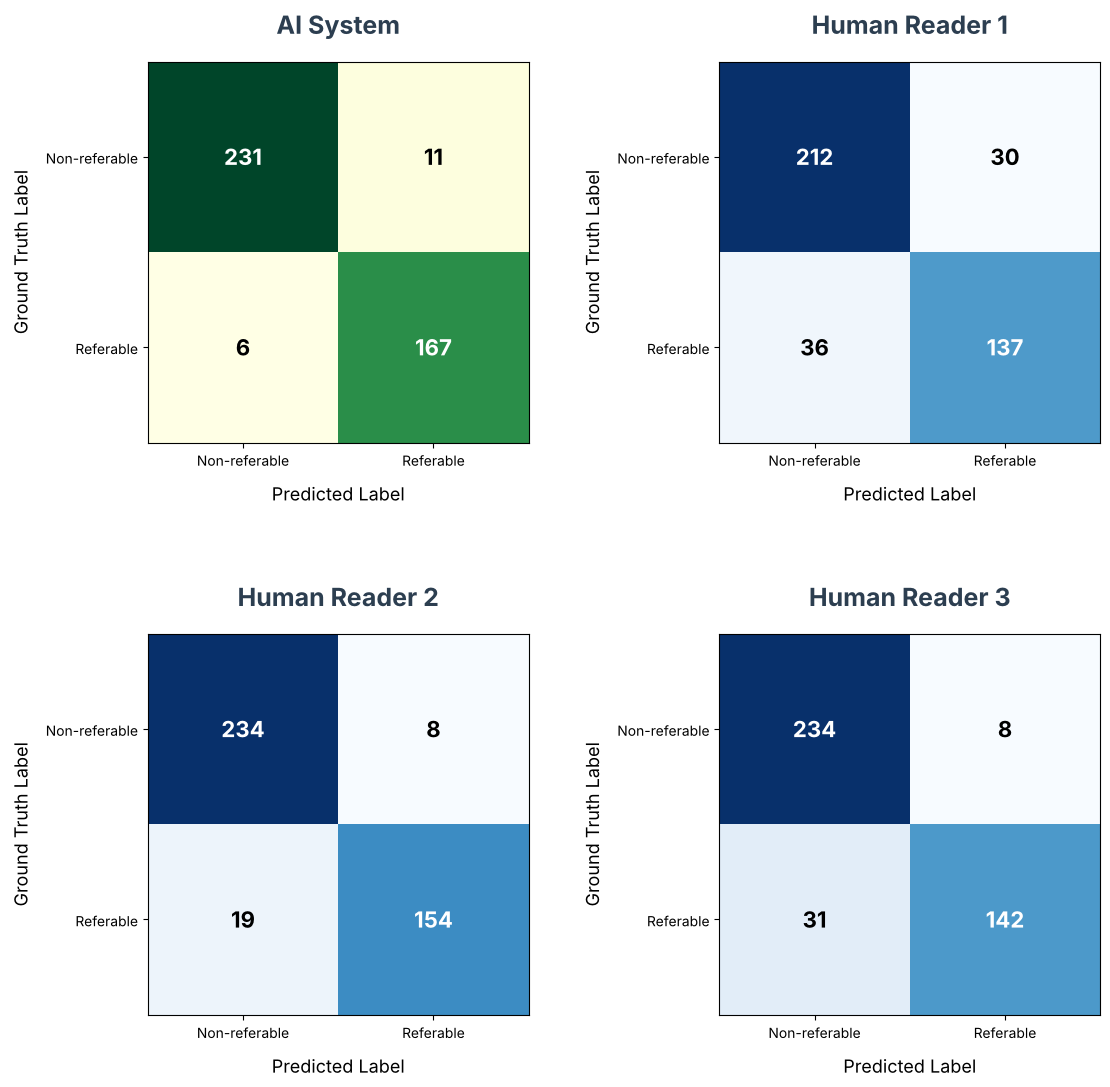

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 12))
tick_labels = ["Non-referable", "Referable"]
for ax, (name, row) in zip(axes.flat, binary_counts.iterrows()):
    cm = np.array([[row["TN"], row["FP"]], [row["FN"], row["TP"]]], dtype=int)
    ax.imshow(cm, cmap="YlGn" if name == "AI" else "Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v:d}", ha="center", va="center", fontsize=16, fontweight="bold",
                color="white" if v > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(tick_labels); ax.set_yticks([0, 1]); ax.set_yticklabels(tick_labels)
    ax.set_title("AI System" if name == "AI" else f"Human {name}", fontsize=18, fontweight="bold", pad=20, color="#2c3e50")
    ax.set_xlabel("Predicted Label", fontsize=13, labelpad=10); ax.set_ylabel("Ground Truth Label", fontsize=13, labelpad=10)
fig.tight_layout(pad=4.0)
fig.savefig(OUT_DIR / "Fig3.tif", dpi=300, bbox_inches="tight", facecolor="white", pil_kwargs={"compression": "tiff_lzw"})
plt.show()

### Composition of referable DR, macular-edema-only cases and missed cases

The model's referable call cannot capture cases that are referable by macular edema alone. This cell counts them, shows how the model and the readers classified them, and describes the model's false negatives.

In [12]:
edema_gt = df[GT_EDEMA].fillna(0).eq(1)
icdr_ref = df[GT_ICDR] >= RDR_CUTOFF
edema_only = ~icdr_ref & edema_gt
missed = df["gt_rdr"].eq(1) & df["ai_rdr"].eq(0)
composition = pd.Series({
    "Referable DR (reference)":                 int(df["gt_rdr"].sum()),
    "  ICDR >= 2":                              int(icdr_ref.sum()),
    "  ICDR >= 2 with macular edema":           int((icdr_ref & edema_gt).sum()),
    "  macular edema alone (ICDR 0 or 1)":      int(edema_only.sum()),
    "Macular edema-only cases referred: AI":    int(df.loc[edema_only, "ai_rdr"].sum()),
    **{f"Macular edema-only cases referred: {n}": int(df.loc[edema_only, c].sum()) for n, _, c in RATERS[1:]},
    "Model false negatives":                    int(missed.sum()),
    "  moderate NPDR":                          int((missed & df[GT_ICDR].eq(2)).sum()),
    "  moderate NPDR with macular edema":       int((missed & df[GT_ICDR].eq(2) & edema_gt).sum()),
    "  macular edema alone":                    int((missed & edema_only).sum()),
    "  severe NPDR or PDR":                     int((missed & df[GT_ICDR].ge(3)).sum()),
})
composition.to_csv(OUT_DIR / "rdr_composition.csv", header=["n images"])
composition.to_frame("n images")

,n images
Referable DR (reference),173
ICDR >= 2,168
ICDR >= 2 with macular edema,107
macular edema alone (ICDR 0 or 1),5
Macular edema-only cases referred: AI,3
Macular edema-only cases referred: Reader 1,3
Macular edema-only cases referred: Reader 2,2
Macular edema-only cases referred: Reader 3,1
Model false negatives,6
moderate NPDR,4


### S4 Table. Referable DR defined by ICDR grade alone (same task for all raters, Wilson 95% CI)

In [13]:
def binary_wilson(y_true, y_pred):
    c = counts(y_true, y_pred)
    tp, fn, fp, tn = c["TP"], c["FN"], c["FP"], c["TN"]
    return {"Accuracy (%) [95% CI]": pct_ci(tp + tn, tp + tn + fp + fn), "Sensitivity (%) [95% CI]": pct_ci(tp, tp + fn),
            "Specificity (%) [95% CI]": pct_ci(tn, tn + fp), **{k: int(v) for k, v in c.items()}}

s4_table = pd.DataFrame({name: binary_wilson(icdr_ref.astype(int), (df[col] >= RDR_CUTOFF).astype(int))
                         for name, col, _ in RATERS}).T
s4_table.to_csv(OUT_DIR / "S4_Table_rdr_icdr_only.csv")
s4_table

,Accuracy (%) [95% CI],Sensitivity (%) [95% CI],Specificity (%) [95% CI],TP,FN,FP,TN
AI,95.7 [93.2–97.2],97.6 [94.0–99.1],94.3 [90.7–96.6],164,4,14,233
Reader 1,79.3 [75.1–82.9],49.4 [41.9–56.9],99.6 [97.7–99.9],83,85,1,246
Reader 2,92.8 [89.9–94.9],85.1 [79.0–89.7],98.0 [95.3–99.1],143,25,5,242
Reader 3,87.0 [83.4–89.9],71.4 [64.2–77.7],97.6 [94.8–98.9],120,48,6,241


### S6 Table. Vision-threatening DR (Wilson 95% CI)

Vision-threatening DR (VTDR) in the reference standard = severe NPDR, PDR and/or macular edema. The first two rows ask whether these images were referred at the referable threshold (model ICDR ≥ 2); the last two ask whether the model graded them as severe NPDR or worse (model ICDR ≥ 3).

In [14]:
gt_vtdr = (df[GT_ICDR].ge(3) | edema_gt).astype(int)
gt_sev  = df[GT_ICDR].ge(3).astype(int)
ai_sev  = df[AI_ICDR].ge(3).astype(int)
s6_table = pd.DataFrame({
    "VTDR referred (model ICDR >= 2)":                       binary_wilson(gt_vtdr, df["ai_rdr"]),
    "Severe NPDR or PDR referred (model ICDR >= 2)":         binary_wilson(gt_sev, df["ai_rdr"]),
    "VTDR graded as severe NPDR or PDR (model ICDR >= 3)":   binary_wilson(gt_vtdr, ai_sev),
    "Severe NPDR or PDR graded as such (model ICDR >= 3)":   binary_wilson(gt_sev, ai_sev),
}).T.drop(columns="Accuracy (%) [95% CI]")
s6_table.to_csv(OUT_DIR / "S6_Table_vtdr.csv")
s6_table

,Sensitivity (%) [95% CI],Specificity (%) [95% CI],TP,FN,FP,TN
VTDR referred (model ICDR >= 2),97.7 [93.3–99.2],81.5 [76.6–85.6],125,3,53,234
Severe NPDR or PDR referred (model ICDR >= 2),100.0 [94.2–100.0],67.1 [62.1–71.8],62,0,116,237
VTDR graded as severe NPDR or PDR (model ICDR >= 3),28.9 [21.8–37.3],99.0 [97.0–99.6],37,91,3,284
Severe NPDR or PDR graded as such (model ICDR >= 3),53.2 [41.0–65.1],98.0 [96.0–99.0],33,29,7,346


### S3 Table. Predictive values at the observed and at community prevalences

At the observed prevalence (41.7%), PPV and NPV and their intervals come directly from the cluster bootstrap. At 20%, 10% and 5% they are projected by Bayes' theorem holding sensitivity and specificity constant, and the intervals propagate the bootstrap uncertainty in sensitivity and specificity.

In [15]:
def ppv_npv(se, sp, prev):
    return (se * prev / (se * prev + (1 - sp) * (1 - prev)) * 100,
            sp * (1 - prev) / (sp * (1 - prev) + (1 - se) * prev) * 100)

obs_prev = df["gt_rdr"].mean()
rows = []
for name in NAMES:
    se, sp = point[name]["rDR Sensitivity"] / 100, point[name]["rDR Specificity"] / 100
    se_b, sp_b = reps[name]["rDR Sensitivity"] / 100, reps[name]["rDR Specificity"] / 100
    for prev in [obs_prev, 0.20, 0.10, 0.05]:
        ppv, npv = ppv_npv(se, sp, prev)
        ppv_b, npv_b = (reps[name]["rDR PPV"], reps[name]["rDR NPV"]) if prev == obs_prev else ppv_npv(se_b, sp_b, prev)
        rows.append({"Rater": name, "rDR prevalence (%)": round(prev * 100, 1),
                     "PPV (%) [95% CI]": f"{ppv:.1f} [{ppv_b.quantile(.025):.1f}–{ppv_b.quantile(.975):.1f}]",
                     "NPV (%) [95% CI]": f"{npv:.1f} [{npv_b.quantile(.025):.1f}–{npv_b.quantile(.975):.1f}]"})
s3_table = pd.DataFrame(rows).set_index(["Rater", "rDR prevalence (%)"])
s3_table.to_csv(OUT_DIR / "S3_Table_ppv_npv_by_prevalence.csv")
s3_table

PPV (%) [95% CI]  NPV (%) [95% CI]
Rater    rDR prevalence (%)                                    
AI       41.7                93.8 [89.8–97.1]  97.5 [95.3–99.2]
         20.0                84.2 [76.5–92.0]  99.1 [98.3–99.7]
         10.0                70.2 [59.1–83.6]  99.6 [99.2–99.9]
         5.0                 52.8 [40.6–70.6]  99.8 [99.6–99.9]
Reader 1 41.7                82.0 [74.8–88.1]  85.5 [80.7–89.8]
         20.0                61.5 [53.7–70.8]  94.4 [92.7–96.0]
         10.0                41.5 [34.0–51.9]  97.4 [96.6–98.2]
         5.0                 25.2 [19.6–33.8]  98.8 [98.4–99.1]
Reader 2 41.7                95.1 [90.8–98.3]  92.5 [89.0–95.7]
         20.0                87.1 [78.1–95.2]  97.2 [96.0–98.4]
         10.0                74.9 [61.3–89.7]  98.8 [98.2–99.3]
         5.0                 58.6 [42.9–80.5]  99.4 [99.1–99.7]
Reader 3 41.7                94.7 [90.2–98.3]  88.3 [83.9–92.2]
         20.0                86.1 [77.1–94.8]  95.6 [94.1–96.9]
         10.0                73.4 [59.9–89.0]  98.0 [97.3–98.6]
         5.0                 56.7 [41.4–79.3]  99.0 [98.7–99.3]

## 7. S5 Table. Paired comparisons between the model and each reader

All raters graded the same 415 images. For each reader: the difference (model − reader) with a cluster-bootstrap 95% CI from the replicates of section 4, and the exact McNemar test on the discordant pairs of correct and incorrect classifications (for sensitivity and specificity, among reference-positive and reference-negative images). The last row of each metric compares the model with the mean of the three readers.

In [16]:
def mcnemar_p(a_correct, b_correct):
    b, c = int((a_correct & ~b_correct).sum()), int((~a_correct & b_correct).sum())
    return b, c, mcnemar([[0, b], [c, 0]], exact=True).pvalue

subset = {"rDR Accuracy": df.index == df.index, "rDR Sensitivity": df["gt_rdr"].eq(1).to_numpy(),
          "rDR Specificity": df["gt_rdr"].eq(0).to_numpy(), "MC Accuracy": df.index == df.index}
rows = []
for metric in ["rDR Accuracy", "rDR Sensitivity", "rDR Specificity", "rDR Kappa", "MC Accuracy", "MC Kappa (quadratic)"]:
    for name in NAMES[1:] + ["Mean of readers"]:
        if name == "Mean of readers":
            est = point["AI"][metric] - np.mean([point[n][metric] for n in NAMES[1:]])
            dist = reps["AI"][metric] - reps[NAMES[1:]].xs(metric, axis=1, level=1).mean(axis=1)
        else:
            est, dist = point["AI"][metric] - point[name][metric], reps["AI"][metric] - reps[name][metric]
        b = c = p = np.nan
        if name != "Mean of readers" and metric in subset:
            sub = df[subset[metric]]
            truth, ai_col, r_col = ((GT_ICDR, AI_ICDR, READERS[name][0]) if metric == "MC Accuracy"
                                    else ("gt_rdr", "ai_rdr", f"rdr_{name}"))
            b, c, p = mcnemar_p(sub[ai_col].astype(int).eq(sub[truth]), sub[r_col].astype(int).eq(sub[truth]))
        lo, hi = dist.quantile([0.025, 0.975])
        rows.append({"Metric": metric, "Model vs": name, "Difference (model − reader)": est, "95% CI low": lo,
                     "95% CI high": hi, "Model correct / reader wrong": b, "Model wrong / reader correct": c,
                     "McNemar exact p": p})
s5_table = pd.DataFrame(rows).set_index(["Metric", "Model vs"])
s5_table.to_csv(OUT_DIR / "S5_Table_paired_comparisons.csv")
s5_table.round(3)

Difference (model − reader)  95% CI low  95% CI high  Model correct / reader wrong  Model wrong / reader correct  McNemar exact p
Metric               Model vs                                                                                                                                          
rDR Accuracy         Reader 1                              11.807       8.374       15.476                          58.0                           9.0            0.000
                     Reader 2                               2.410      -0.243        5.061                          19.0                           9.0            0.087
                     Reader 3                               5.301       2.358        8.497                          30.0                           8.0            0.000
                     Mean of readers                        6.506       4.105        9.048                           NaN                           NaN              NaN
rDR Sensitivity      Reader 1                              17.341      11.250       23.597                          32.0                           2.0            0.000
                     Reader 2                               7.514       2.645       12.580                          15.0                           2.0            0.002
                     Reader 3                              14.451       8.973       20.469                          25.0                           0.0            0.000
                     Mean of readers                       13.102       8.721       17.903                           NaN                           NaN              NaN
rDR Specificity      Reader 1                               7.851       3.629       12.501                          26.0                           7.0            0.001
                     Reader 2                              -1.240      -4.065        1.304                           4.0                           7.0            0.549
                     Reader 3                              -1.240      -4.115        1.681                           5.0                           8.0            0.581
                     Mean of readers                        1.791      -0.675        4.149                           NaN                           NaN              NaN
rDR Kappa            Reader 1                               0.245       0.175        0.322                           NaN                           NaN              NaN
                     Reader 2                               0.051      -0.004        0.106                           NaN                           NaN              NaN
                     Reader 3                               0.113       0.052        0.178                           NaN                           NaN              NaN
                     Mean of readers                        0.136       0.088        0.190                           NaN                           NaN              NaN
MC Accuracy          Reader 1                              15.181       9.615       21.080                         105.0                          42.0            0.000
                     Reader 2                               9.398       4.116       14.727                          86.0                          47.0            0.001
                     Reader 3                              16.386      10.922       21.876                         110.0                          42.0            0.000
                     Mean of readers                       13.655       8.883       18.414                           NaN                           NaN              NaN
MC Kappa (quadratic) Reader 1                               0.201       0.137        0.274                           NaN                           NaN              NaN
                     Reader 2                               0.024      -0.007        0.054                           NaN                           NaN              NaN
      

## 8. Figure 1. DRStageNet against the human readers

Bars are point estimates; error bars are cluster-bootstrap 95% CIs. The human bar is the mean of the three readers, and its interval is the distribution of that mean across the bootstrap replicates.

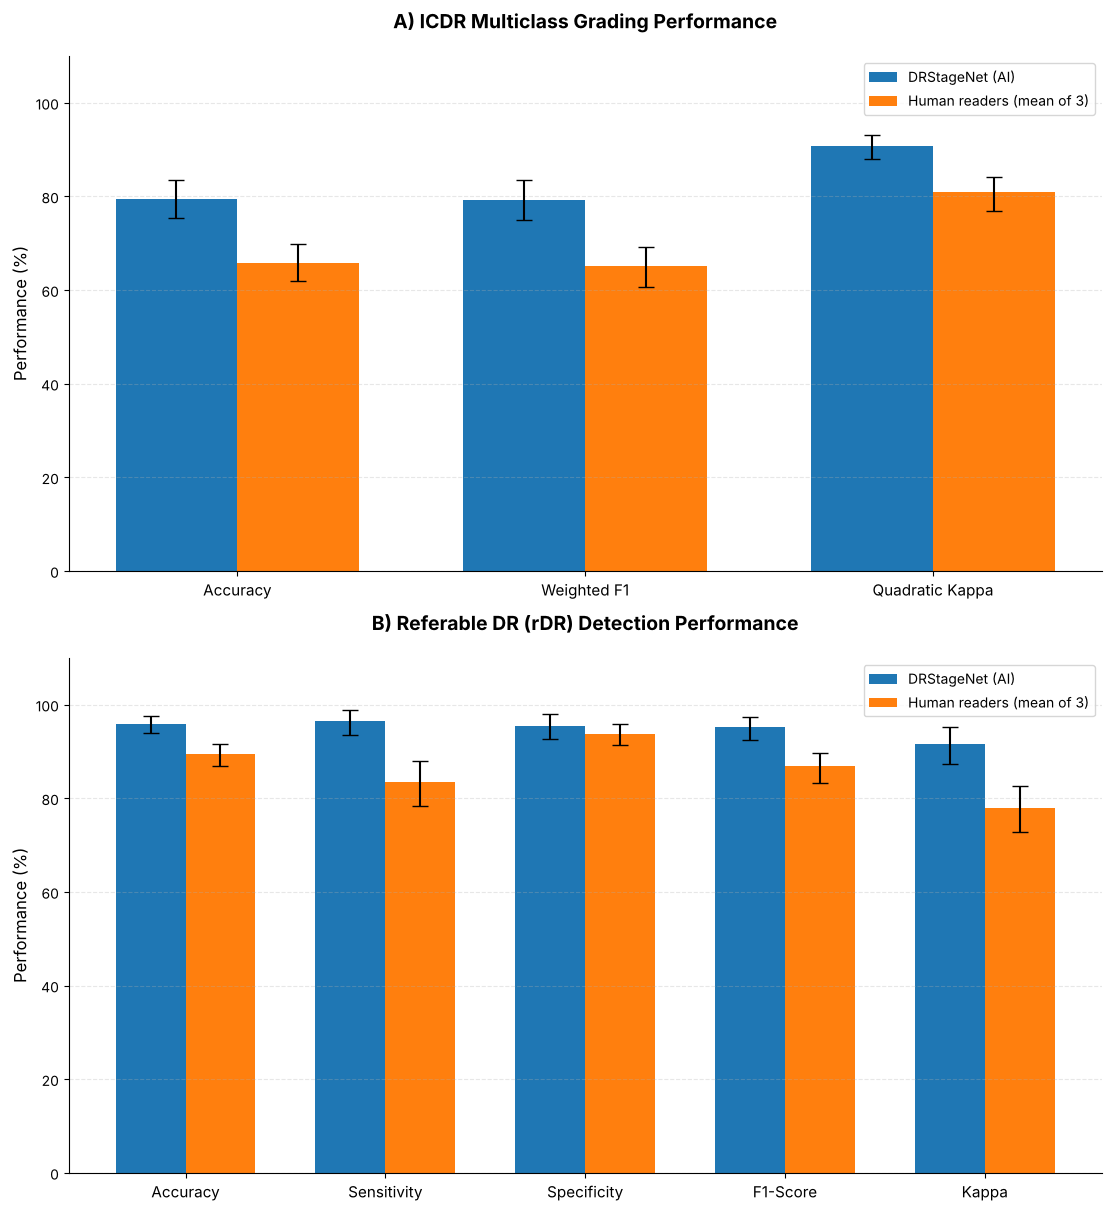

In [17]:
def _panel(ax, metrics, labels, title):
    x, w = np.arange(len(metrics)), 0.35
    ai_est, ai_rep = np.array([point["AI"][m] for m in metrics]), reps["AI"][metrics]
    hu_est = np.mean([[point[n][m] for m in metrics] for n in NAMES[1:]], axis=0)
    hu_rep = sum(reps[n][metrics] for n in NAMES[1:]) / len(NAMES[1:])
    scale = np.array([1 if any(k in m for k in ("Accuracy", "Sensitivity", "Specificity")) else 100 for m in metrics])
    for off, est, rp, color, label in [(-w / 2, ai_est, ai_rep, "#1f77b4", "DRStageNet (AI)"),
                                       (+w / 2, hu_est, hu_rep, "#ff7f0e", "Human readers (mean of 3)")]:
        lo, hi = rp.quantile(0.025).to_numpy(), rp.quantile(0.975).to_numpy()
        ax.bar(x + off, est * scale, w, yerr=np.vstack([est - lo, hi - est]) * scale, color=color, label=label, capsize=6)
    ax.set_title(title, fontsize=14, fontweight="bold", pad=20)
    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=11)
    ax.set_ylabel("Performance (%)", fontsize=12); ax.set_ylim(0, 110)
    ax.legend(loc="upper right", fontsize=10, frameon=True)
    ax.grid(axis="y", linestyle="--", alpha=0.3); ax.spines[["top", "right"]].set_visible(False)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 12), constrained_layout=True)
_panel(ax1, ["MC Accuracy", "MC Weighted F1", "MC Kappa (quadratic)"], ["Accuracy", "Weighted F1", "Quadratic Kappa"],
       "A) ICDR Multiclass Grading Performance")
_panel(ax2, ["rDR Accuracy", "rDR Sensitivity", "rDR Specificity", "rDR F1", "rDR Kappa"],
       ["Accuracy", "Sensitivity", "Specificity", "F1-Score", "Kappa"], "B) Referable DR (rDR) Detection Performance")
fig.savefig(OUT_DIR / "Figure_1.tif", dpi=300, bbox_inches="tight", pil_kwargs={"compression": "tiff_lzw"})
plt.show()

## 9. Error analysis of the five-class grades

A high-magnitude error is an absolute difference of two or more grades between the model and the reference standard. The qualitative review of these images (artefacts and non-diabetic retinal findings) was recorded by a retina specialist in `REVIEW_CSV`; only aggregate counts are shown.

In [18]:
delta = df[AI_ICDR].astype(int) - df[GT_ICDR]
is_err = delta.ne(0)
high = delta.abs().ge(2)
cm_ai = s1_table.loc["AI"]
error_summary = pd.Series({
    "Misclassified images":                   int(is_err.sum()),
    "  one grade apart":                      int(delta.abs().eq(1).sum()),
    "  one grade apart (% of errors)":        round(delta.abs().eq(1).sum() / is_err.sum() * 100, 1),
    "  two or more grades apart":             int(high.sum()),
    "    overestimation":                     int((high & delta.gt(0)).sum()),
    "    underestimation":                    int((high & delta.lt(0)).sum()),
    "Largest discrepancy (grades)":           int(delta.abs().max()),
    "Severe NPDR graded as moderate NPDR":    int(cm_ai.loc["Severe NPDR", "Moderate NPDR"]),
    "No DR graded as mild NPDR":              int(cm_ai.loc["No DR", "Mild NPDR"]),
})
error_summary.to_csv(OUT_DIR / "error_summary.csv", header=["value"])
display(error_summary.to_frame("value"))

if REVIEW_CSV.exists():
    review = pd.read_csv(REVIEW_CSV)
    for c in ["artefacts", "other_disease"]:
        review[c] = review[c].astype(str).str.strip().str.lower().eq("yes")
    assert set(review["ImageID"]) == set(df.loc[is_err, IMAGE]), "review sheet does not match the current errors"
    hr = review[review["abs_delta"] >= 2]
    ilm = hr["which"].astype(str).str.contains("ilm", case=False)
    qual = pd.Series({"High-magnitude errors reviewed": len(hr),
                      "With artefacts": int(hr["artefacts"].sum()),
                      "With non-diabetic retinal findings": int(hr["other_disease"].sum()),
                      "  of which ILM reflex": int((hr["other_disease"] & ilm).sum())})
    qual.to_csv(OUT_DIR / "error_review_summary.csv", header=["n images"])
    display(qual.to_frame("n images"))

,value
Misclassified images,85.0
one grade apart,73.0
one grade apart (% of errors),85.9
two or more grades apart,12.0
overestimation,7.0
underestimation,5.0
Largest discrepancy (grades),2.0
Severe NPDR graded as moderate NPDR,25.0
No DR graded as mild NPDR,17.0


,n images
High-magnitude errors reviewed,12
With artefacts,6
With non-diabetic retinal findings,7
of which ILM reflex,3


## 10. Figure 2. Example images

Needs the retinal images in `IMAGES_DIR`, which are not distributed. The selection is deterministic: the first image(s) of each outcome group in file order, among untreated eyes, with referable status defined by ICDR grade.

In [19]:
if not IMAGES_DIR.exists():
    print(f"{IMAGES_DIR} not found; Figure 2 not generated.")
else:
    from PIL import Image, ImageDraw

    def circular_crop(img, zoom=0.92):
        img = img.convert("RGB"); w, h = img.size
        cx, cy, r = w / 2, h / 2, min(w, h) / 2 * zoom
        box = (cx - r, cy - r, cx + r, cy + r)
        mask = Image.new("L", (w, h), 0); ImageDraw.Draw(mask).ellipse(box, fill=255)
        return Image.composite(img, Image.new("RGB", (w, h)), mask).crop(box)

    f2 = raw[~treated]
    gt_ref, ai_ref = f2[GT_ICDR] >= RDR_CUTOFF, f2[AI_ICDR] >= RDR_CUTOFF
    tn, tp, fp, fn = f2[~gt_ref & ~ai_ref], f2[gt_ref & ai_ref], f2[~gt_ref & ai_ref], f2[gt_ref & ~ai_ref]
    picks = [(tn.iloc[0], "AGREEMENT"), (fp.iloc[0], "FALSE POSITIVE"), (fn.iloc[0], "FALSE NEGATIVE"),
             (tp.iloc[0], "AGREEMENT"), (fp.iloc[1], "FALSE POSITIVE"), (fn.iloc[1], "FALSE NEGATIVE")]
    fig, axes = plt.subplots(2, 3, figsize=(18, 15), facecolor="white")
    fig.text(0.5, 0.96, "Non-referable Diabetic Retinopathy Context", ha="center", fontsize=22, fontweight="bold")
    fig.text(0.5, 0.46, "Referable Diabetic Retinopathy Context", ha="center", fontsize=22, fontweight="bold")
    yn = lambda v: "Yes" if v >= RDR_CUTOFF else "No"
    for ax, (row, status) in zip(axes.flat, picks):
        ax.imshow(circular_crop(Image.open(IMAGES_DIR / row[IMAGE])))
        ax.set_title(f"{status}\nGT: {yn(row[GT_ICDR])} | AI: {yn(row[AI_ICDR])}", fontsize=15, fontweight="semibold", pad=20)
        ax.axis("off")
    fig.subplots_adjust(hspace=0.7, wspace=0.1, top=0.90, bottom=0.05, left=0.05, right=0.95)
    fig.savefig(OUT_DIR / "Fig2.tif", dpi=300, bbox_inches="tight", pil_kwargs={"compression": "tiff_lzw"})
    plt.show()

data/images not found; Figure 2 not generated.


## 11. Check of the key results reported in the manuscript

Each row compares a value reported in the revised manuscript with the value recomputed above, at the precision reported.

In [20]:
ai_m, s5 = multi.loc["AI"], s5_table
reported = [  # (item, reported value, recomputed value, decimals)
    ("Images acquired", 489, N_ACQUIRED_IMG, 0), ("Excluded: previous treatment", 57, n_treated, 0),
    ("Excluded: ungradable", 17, n_ungradable, 0), ("Images analysed", 415, len(df), 0),
    ("Patients analysed", 252, df[PATIENT].nunique(), 0),
    ("Patients with both eyes", 163, sum(len(g) == 2 for g in groups), 0),
    ("Inter-grader unweighted kappa", 0.734, intergrader["ICDR unweighted kappa"], 3),
    ("Inter-grader quadratic kappa", 0.889, intergrader["ICDR quadratic weighted kappa"], 3),
    ("Inter-grader macular edema kappa", 0.874, intergrader["Macular edema kappa"], 3),
    ("Referable DR (reference)", 173, composition["Referable DR (reference)"], 0),
    ("Macular-edema-only referable cases", 5, composition["  macular edema alone (ICDR 0 or 1)"], 0),
    ("Five-class accuracy (%)", 79.5, point["AI"]["MC Accuracy"], 1),
    ("Macro precision", 0.676, ai_m["Macro precision"], 3), ("Macro recall", 0.622, ai_m["Macro recall"], 3),
    ("Macro F1", 0.635, ai_m["Macro F1"], 3), ("Weighted F1", 0.793, ai_m["Weighted F1"], 3),
    ("Unweighted kappa", 0.679, ai_m["Unweighted kappa"], 3),
    ("Quadratic weighted kappa", 0.908, ai_m["Quadratic weighted kappa"], 3),
    ("Quadratic kappa 95% CI low", 0.881, ci.loc[("AI", "MC Kappa (quadratic)"), "ci_low"], 3),
    ("Quadratic kappa 95% CI high", 0.931, ci.loc[("AI", "MC Kappa (quadratic)"), "ci_high"], 3),
    ("rDR accuracy (%)", 95.9, point["AI"]["rDR Accuracy"], 1),
    ("rDR sensitivity (%)", 96.5, point["AI"]["rDR Sensitivity"], 1),
    ("rDR sensitivity 95% CI low", 93.5, ci.loc[("AI", "rDR Sensitivity"), "ci_low"], 1),
    ("rDR sensitivity 95% CI high", 98.9, ci.loc[("AI", "rDR Sensitivity"), "ci_high"], 1),
    ("rDR specificity (%)", 95.5, point["AI"]["rDR Specificity"], 1),
    ("rDR specificity 95% CI low", 92.6, ci.loc[("AI", "rDR Specificity"), "ci_low"], 1),
    ("rDR specificity 95% CI high", 97.9, ci.loc[("AI", "rDR Specificity"), "ci_high"], 1),
    ("rDR PPV (%)", 93.8, point["AI"]["rDR PPV"], 1), ("rDR NPV (%)", 97.5, point["AI"]["rDR NPV"], 1),
    ("rDR F1, referable class", 0.952, point["AI"]["rDR F1"], 3), ("rDR kappa", 0.916, point["AI"]["rDR Kappa"], 3),
    ("Model false negatives", 6, binary_counts.loc["AI", "FN"], 0),
    ("Model false positives", 11, binary_counts.loc["AI", "FP"], 0),
    ("rDR accuracy, model − mean of readers (points)", 6.5, s5.loc[("rDR Accuracy", "Mean of readers"), "Difference (model − reader)"], 1),
    ("rDR accuracy, model − Reader 2 (points)", 2.4, s5.loc[("rDR Accuracy", "Reader 2"), "Difference (model − reader)"], 1),
    ("rDR accuracy vs Reader 2, McNemar p", 0.087, s5.loc[("rDR Accuracy", "Reader 2"), "McNemar exact p"], 3),
    ("Kappa, model vs Grader A alone", 0.898, kappa_ctx["DRStageNet vs Grader A alone"], 3),
    ("Kappa, model vs Grader B alone", 0.882, kappa_ctx["DRStageNet vs Grader B alone"], 3),
    ("Misclassified images", 85, error_summary["Misclassified images"], 0),
    ("Errors one grade apart (%)", 85.9, error_summary["  one grade apart (% of errors)"], 1),
    ("Errors of two or more grades", 12, error_summary["  two or more grades apart"], 0),
]
check = pd.DataFrame([{"Item": i, "Reported": r, "Recomputed": round(float(v), d), "ok": round(float(v), d) == r}
                      for i, r, v, d in reported])
check.to_csv(OUT_DIR / "manuscript_check.csv", index=False)
print(f"{check['ok'].sum()} of {len(check)} reported values reproduced.")
check if not check["ok"].all() else check.tail(3)

41 of 41 reported values reproduced.


,Item,Reported,Recomputed,ok
38,Misclassified images,85.0,85.0,True
39,Errors one grade apart (%),85.9,85.9,True
40,Errors of two or more grades,12.0,12.0,True
